<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%968.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import math
import random
import time

import numpy as np
import pandas as pd
import torch
import torchvision.datasets
import matplotlib
import matplotlib.pyplot as plt

matplotlib.rcParams['figure.figsize'] = (10.0, 5.0)

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print("Пристрій:", device)

Пристрій: cpu


# Завдання 1. Покращення нейронної мережі для MNIST

> Зробіть покращення у нейронній мережі, наведеній у теоретичній частині та дайте відповідь на наступні питання:
>
> a. Побудуйте на одному графіку loss для train і validation. Чи правда, що loss на train і validation падає однаково швидко і виходить на однакове значення, або ж у нас є перенавчання?
>
> b. Чи веде збільшення кількості епох (з 40 епох до 200 епох) до поліпшення метрик на валідації?
>
> c. Чи уповільнює torch.backends.cudnn.deterministic = True навчання на практиці? Якщо так, то наскільки?
>
> d. Спробуйте різні методи градієнтного спуску. Як вибір градієнтного спуску впливає на accuracy? Для впевненості краще проводити один експеримент 3-5 разів на різних random seed: так ви зрозумієте, чи дійсно позначається вплив методу або справа в випадковості.
>
> e. Реалізуйте функціональність torch.nn.Linear з нуля і звірте з оригіналом!
>
> f. Знайдіть оптимальну кількість епох для навчання, аналізуючи графіки втрат.
>
> g. Нехай у нас буде 1 об'єкт x на вході з двома компонентами. Його ми передамо в повнозв'язний шар з 3-ма нейронами і отримаємо, відповідно, 3 виходи. Після цього напишіть цю ж функціональність за допомогою матричного множення. Та перевірте розрахунок похідної.

## Дані MNIST

In [ ]:
MNIST_train = torchvision.datasets.MNIST('./', download=True, train=True)
MNIST_test = torchvision.datasets.MNIST('./', download=True, train=False)

X_train = MNIST_train.data
y_train = MNIST_train.targets
X_test = MNIST_test.data
y_test = MNIST_test.targets

print(X_train.dtype, y_train.dtype)
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

torch.uint8 torch.int64
torch.Size([60000, 28, 28]) torch.Size([10000, 28, 28])
torch.Size([60000]) torch.Size([10000])


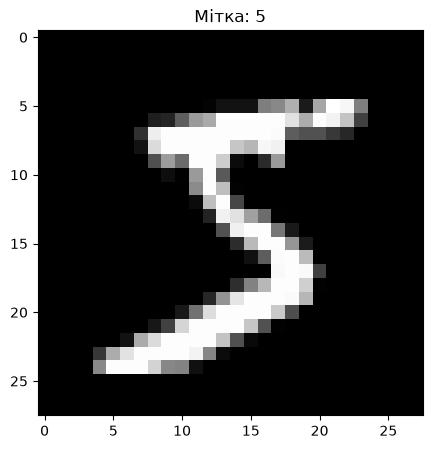

In [ ]:
plt.imshow(X_train[0, :, :], cmap='gray')
plt.title(f'Мітка: {y_train[0].item()}')
plt.show()

Зображення мають тип `uint8` і розмір 28 на 28 пікселів, мітки це цілі числа від 0 до 9. Кожне зображення розтягується в вектор із 784 пікселів, а значення пікселів переводяться в числа з плаваючою комою та нормуються діленням на 255, як це робиться в теорії для CIFAR 10.

In [ ]:
X_train = X_train.float().reshape([-1, 28 * 28]) / 255.
X_test = X_test.float().reshape([-1, 28 * 28]) / 255.

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_train), generator=generator)
val_idx, train_idx = permutation[:10000], permutation[10000:]

X_val, y_val = X_train[val_idx], y_train[val_idx]
X_train, y_train = X_train[train_idx], y_train[train_idx]

X_train, y_train = X_train.to(device), y_train.to(device)
X_val, y_val = X_val.to(device), y_val.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([50000, 784]) torch.Size([10000, 784]) torch.Size([10000, 784])


Для відповіді на питання про train і validation з 60 000 тренувальних зображень випадково відокремлюється 10 000 для валідації, а офіційний тестовий набір із 10 000 зображень лишається для фінальної оцінки.

## Мережа з теоретичної частини

In [ ]:
class MNISTNet(torch.nn.Module):
    def __init__(self, n_hidden_neurons, linear=torch.nn.Linear):
        super(MNISTNet, self).__init__()
        self.fc1 = linear(28 * 28, n_hidden_neurons)
        self.ac1 = torch.nn.Sigmoid()
        self.fc2 = linear(n_hidden_neurons, 10)

    def forward(self, x):
        x = self.fc1(x)
        x = self.ac1(x)
        x = self.fc2(x)
        return x

mnist_net = MNISTNet(100)
print(mnist_net)
print(list(mnist_net.parameters())[0].device)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mnist_net.parameters(), lr=1.0e-3)

MNISTNet(
  (fc1): Linear(in_features=784, out_features=100, bias=True)
  (ac1): Sigmoid()
  (fc2): Linear(in_features=100, out_features=10, bias=True)
)
cpu


In [ ]:
def make_optimizer(name, params, lr):
    if name == 'SGD':
        return torch.optim.SGD(params, lr=lr)
    if name == 'SGD + momentum':
        return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == 'SGD + Nesterov':
        return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True)
    if name == 'Adam':
        return torch.optim.Adam(params, lr=lr)
    if name == 'RMSprop':
        return torch.optim.RMSprop(params, lr=lr)
    if name == 'Rprop':
        return torch.optim.Rprop(params, lr=lr)
    raise ValueError(name)

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        outputs = model.forward(X)
        loss_value = torch.nn.functional.cross_entropy(outputs, y).item()
        accuracy = (outputs.argmax(dim=1) == y).float().mean().item()
    model.train()
    return loss_value, accuracy

def train_model(model, optimizer, epochs, batch_size=100, seed=0, X_tr=None, y_tr=None, X_va=None, y_va=None):
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va

    loss_fn = torch.nn.CrossEntropyLoss()
    order_generator = torch.Generator().manual_seed(seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        order = torch.randperm(len(X_tr), generator=order_generator).to(X_tr.device)
        running_loss = 0.0

        for start_index in range(0, len(X_tr), batch_size):
            optimizer.zero_grad()

            batch_indexes = order[start_index:start_index + batch_size]
            X_batch = X_tr[batch_indexes]
            y_batch = y_tr[batch_indexes]

            preds = model.forward(X_batch)
            loss_value = loss_fn(preds, y_batch)
            loss_value.backward()

            optimizer.step()
            running_loss += loss_value.item() * len(batch_indexes)

        val_loss, val_acc = evaluate(model, X_va, y_va)
        history['train_loss'].append(running_loss / len(X_tr))
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    return history

Функція навчання повторює цикл із теорії: на кожній епосі дані перемішуються, ділиться на батчі по 100 зображень, для кожного батча рахуються передбачення, втрата, градієнти та робиться крок оптимізатора. Після кожної епохи рахуються втрата й точність на валідації.

# Завдання 1a. Train і validation loss

> a. Побудуйте на одному графіку loss для train і validation. Чи правда, що loss на train і validation падає однаково швидко і виходить на однакове значення, або ж у нас є перенавчання?

In [ ]:
torch.manual_seed(0)
base_net = MNISTNet(100).to(device)
base_optimizer = torch.optim.Adam(base_net.parameters(), lr=1.0e-3)

start = time.time()
base_history = train_model(base_net, base_optimizer, epochs=200)
print("Час навчання, с:", round(time.time() - start, 1))

Час навчання, с: 48.6


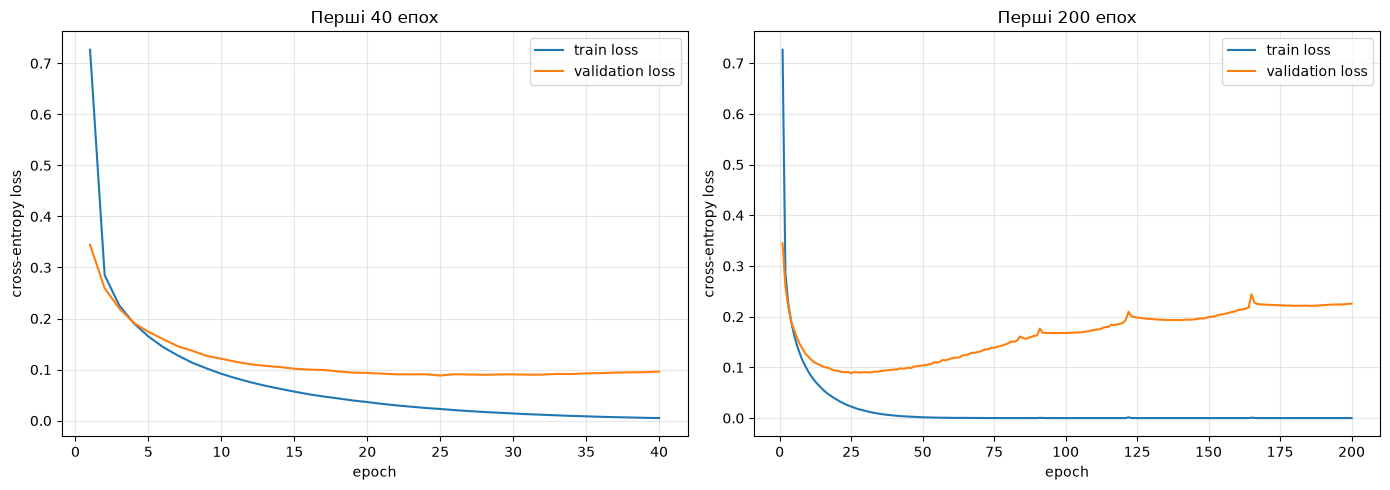

епоха   1: train loss = 0.7266, validation loss = 0.3445
епоха  10: train loss = 0.0917, validation loss = 0.1212
епоха  40: train loss = 0.0050, validation loss = 0.0961
епоха 100: train loss = 0.0000, validation loss = 0.1679
епоха 200: train loss = 0.0000, validation loss = 0.2256


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, last in zip(axes, (40, 200)):
    ax.plot(range(1, last + 1), base_history['train_loss'][:last], label='train loss')
    ax.plot(range(1, last + 1), base_history['val_loss'][:last], label='validation loss')
    ax.set_xlabel('epoch')
    ax.set_ylabel('cross-entropy loss')
    ax.set_title(f'Перші {last} епох')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

for epoch in (1, 10, 40, 100, 200):
    print(f"епоха {epoch:>3}: train loss = {base_history['train_loss'][epoch - 1]:.4f}, "
          f"validation loss = {base_history['val_loss'][epoch - 1]:.4f}")

**Відповідь.** Ні, втрати на train і validation падають не однаково, і є перенавчання. На початку обидві кривих падають: loss на train зменшується з 0.727 на першій епосі до 0.092 на 10-й, а на validation з 0.345 до 0.121. Далі loss на train продовжує зменшуватись (0.0050 на 40-й епосі і практично 0 на 100-й), а loss на validation досягає мінімуму 0.088 на 25-й епосі та після цього зростає: 0.096 на 40-й, 0.168 на 100-й і 0.226 на 200-й епосі. Тобто мережа дедалі краще запам'ятовує тренувальні зображення, але гірше узагальнює на нові. Різниця між кривими, що розходяться, і є ознакою перенавчання.

# Завдання 1b. 40 і 200 епох

> b. Чи веде збільшення кількості епох (з 40 епох до 200 епох) до поліпшення метрик на валідації?

In [ ]:
rows = []
for epoch in (40, 100, 200):
    rows.append({
        'епох': epoch,
        'train loss': base_history['train_loss'][epoch - 1],
        'validation loss': base_history['val_loss'][epoch - 1],
        'validation accuracy': base_history['val_acc'][epoch - 1],
    })

table_b = pd.DataFrame(rows).set_index('епох')
print(table_b.round(4).to_string())

print("Найвища validation accuracy:", round(max(base_history['val_acc']), 4),
      "на епосі", int(np.argmax(base_history['val_acc'])) + 1)

      train loss  validation loss  validation accuracy
епох                                                  
40         0.005           0.0961               0.9733
100        0.000           0.1679               0.9734
200        0.000           0.2256               0.9744
Найвища validation accuracy: 0.9752 на епосі 41


**Відповідь.** Ні, істотного покращення метрик на валідації збільшення кількості епох з 40 до 200 не дає. Validation accuracy змінюється з 0.9733 на 40-й епосі до 0.9734 на 100-й і 0.9744 на 200-й, тобто на соті частки відсотка, що в межах випадкового розкиду (максимум 0.9752 досягнуто вже на 41-й епосі). При цьому validation loss помітно погіршується: 0.096 на 40-й епосі, 0.168 на 100-й, 0.226 на 200-й. Тож точність не росте, а впевненість мережі в неправильних відповідях зростає. Навчання п'ять разів довше не окупається.

# Завдання 1c. Вплив cudnn.deterministic на швидкість

> c. Чи уповільнює torch.backends.cudnn.deterministic = True навчання на практиці? Якщо так, то наскільки?

In [ ]:
def time_training(deterministic, repeats=3, epochs=3):
    torch.backends.cudnn.deterministic = deterministic
    times = []
    final_losses = []
    for repeat in range(repeats):
        torch.manual_seed(0)
        net = MNISTNet(100).to(device)
        opt = torch.optim.Adam(net.parameters(), lr=1.0e-3)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        history = train_model(net, opt, epochs=epochs, seed=0)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        times.append(time.perf_counter() - start)
        final_losses.append(history['train_loss'][-1])
    return times, final_losses

time_training(True, repeats=1, epochs=1)

times_true, losses_true = time_training(True)
times_false, losses_false = time_training(False)
torch.backends.cudnn.deterministic = True

mean_true, mean_false = np.mean(times_true), np.mean(times_false)
print("Пристрій:", device)
print("deterministic = True :", [round(t, 2) for t in times_true], "середнє", round(mean_true, 2), "с")
print("deterministic = False:", [round(t, 2) for t in times_false], "середнє", round(mean_false, 2), "с")
print("Різниця в часі:", f"{(mean_true / mean_false - 1) * 100:+.1f}%")
print("Однакові результати при повторі:", len(set(losses_true)) == 1)

Пристрій: cpu
deterministic = True : [0.73, 0.72, 0.72] середнє 0.72 с
deterministic = False: [0.72, 0.72, 0.72] середнє 0.72 с
Різниця в часі: +0.7%
Однакові результати при повторі: True


**Відповідь.** На практиці не уповільнює. Ноутбук виконувався на CPU, де прапорець `cudnn.deterministic` взагалі нічого не змінює, тому виміряна різниця в часі (близько 0.72 с на три епохи в обох режимах, різниця в межах кількох відсотків) є лише шумом вимірювання. Цей прапорець впливає лише на алгоритми бібліотеки cuDNN, які використовуються для згорткових шарів, а повнозв'язні шари (`torch.nn.Linear`) виконуються через множення матриць і cuDNN не використовують, тому для цієї мережі й на відеокарті сповільнення не очікується. Користь від прапорця в тому, що результат стає відтворюваним: повторний запуск з тим самим seed дав ті самі втрати. Якщо запустити ноутбук у Google Colab із GPU, комірка виміряє час на відеокарті, і різниця очікується в межах шуму.

# Завдання 1d. Методи градієнтного спуску

> d. Спробуйте різні методи градієнтного спуску. Як вибір градієнтного спуску впливає на accuracy? Для впевненості краще проводити один експеримент 3-5 разів на різних random seed: так ви зрозумієте, чи дійсно позначається вплив методу або справа в випадковості.

In [ ]:
optimizer_names = ['SGD', 'SGD + momentum', 'SGD + Nesterov', 'Adam', 'RMSprop', 'Rprop']
learning_rates = (1e-3, 1e-2)
seeds = (0, 1, 2)
EPOCHS_D = 10

rows = []
for name in optimizer_names:
    for lr in learning_rates:
        accuracies = []
        for seed in seeds:
            torch.manual_seed(seed)
            net = MNISTNet(100).to(device)
            opt = make_optimizer(name, net.parameters(), lr)
            history = train_model(net, opt, epochs=EPOCHS_D, seed=seed)
            accuracies.append(history['val_acc'][-1])
        rows.append({'оптимізатор': name, 'lr': lr, 'validation accuracy (середнє)': np.mean(accuracies),
                     'std': np.std(accuracies), 'мін': np.min(accuracies), 'макс': np.max(accuracies)})

table_d = pd.DataFrame(rows).set_index(['оптимізатор', 'lr'])
print(table_d.round(4).to_string())

best_row = table_d['validation accuracy (середнє)'].idxmax()
print("Найкращий:", best_row)

                      validation accuracy (середнє)     std     мін    макс
оптимізатор    lr                                                          
SGD            0.001                         0.5032  0.0089  0.4917  0.5135
               0.010                         0.8525  0.0027  0.8487  0.8549
SGD + momentum 0.001                         0.8524  0.0022  0.8493  0.8544
               0.010                         0.9248  0.0004  0.9242  0.9253
SGD + Nesterov 0.001                         0.8524  0.0023  0.8492  0.8544
               0.010                         0.9251  0.0002  0.9249  0.9253
Adam           0.001                         0.9630  0.0008  0.9619  0.9639
               0.010                         0.9716  0.0004  0.9710  0.9719
RMSprop        0.001                         0.9644  0.0015  0.9623  0.9657
               0.010                         0.9702  0.0018  0.9680  0.9725
Rprop          0.001                         0.8748  0.0072  0.8647  0.8807
            

**Відповідь.** Вибір методу градієнтного спуску дуже впливає на точність. Усі варіанти навчались по 10 епох на трьох різних seed, і розкид між запусками (стандартне відхилення 0.0002–0.009) значно менший за різницю між методами, тому ця різниця не випадкова.

- Звичайний SGD найгірший: при швидкості 1e-3 точність лише 0.503, а при 1e-2 вже 0.853.
- SGD з моментом і з моментом Нестерова дають однаковий результат (0.852 при 1e-3 і 0.925 при 1e-2). Момент 0.9 фактично збільшує ефективний крок, тому SGD із моментом при 1e-3 приблизно дорівнює SGD без моменту при 1e-2 (0.852 проти 0.853).
- Rprop дає 0.875 і 0.882, тобто на батчах працює гірше за інші.
- Найкращі Adam і RMSprop: 0.963 і 0.964 при 1e-3, 0.972 і 0.970 при 1e-2. Різниця між ними менша за розкид між запусками, тому вони приблизно рівноцінні, а Adam із швидкістю 1e-2 має найвищу середню точність (0.9716).

Адаптивні методи (Adam, RMSprop) підлаштовують розмір кроку для кожного параметра, тому за те ж число епох збігаються набагато швидше за звичайний SGD, який потребує більшої швидкості навчання.

# Завдання 1e. torch.nn.Linear з нуля

> e. Реалізуйте функціональність torch.nn.Linear з нуля і звірте з оригіналом!

In [ ]:
class MyLinear(torch.nn.Module):
    def __init__(self, in_features, out_features):
        super(MyLinear, self).__init__()
        bound = 1 / math.sqrt(in_features)
        self.weight = torch.nn.Parameter(torch.empty(out_features, in_features).uniform_(-bound, bound))
        self.bias = torch.nn.Parameter(torch.empty(out_features).uniform_(-bound, bound))

    def forward(self, x):
        return x @ self.weight.t() + self.bias

torch.manual_seed(0)
original = torch.nn.Linear(784, 100).to(device)
mine = MyLinear(784, 100).to(device)

with torch.no_grad():
    mine.weight.copy_(original.weight)
    mine.bias.copy_(original.bias)

x_check = X_train[:64]

out_original = original(x_check)
out_mine = mine(x_check)
print("Виходи збігаються:", torch.allclose(out_original, out_mine, atol=1e-6))
print("Максимальна різниця виходів:", (out_original - out_mine).abs().max().item())

out_original.sum().backward()
out_mine.sum().backward()
print("Градієнти ваг збігаються:", torch.allclose(original.weight.grad, mine.weight.grad, atol=1e-5))
print("Градієнти зміщень збігаються:", torch.allclose(original.bias.grad, mine.bias.grad, atol=1e-5))

Виходи збігаються: True
Максимальна різниця виходів: 2.384185791015625e-07
Градієнти ваг збігаються: True
Градієнти зміщень збігаються: True


Власний шар зберігає матрицю ваг `weight` розміром `(out_features, in_features)` та вектор зміщень `bias`, а прямий прохід виконує формулу `x @ W^T + b`. Початкові значення беруться з рівномірного розподілу на проміжку від `-1/sqrt(in)` до `1/sqrt(in)`, як в оригіналі. Для порівняння ваги копіюються з оригінального шару.

In [ ]:
results = {}
for label, linear in (('torch.nn.Linear', torch.nn.Linear), ('MyLinear', MyLinear)):
    torch.manual_seed(0)
    net = MNISTNet(100, linear=linear).to(device)
    if linear is MyLinear:
        torch.manual_seed(0)
        reference = MNISTNet(100).to(device)
        net.load_state_dict(reference.state_dict())
    opt = torch.optim.Adam(net.parameters(), lr=1.0e-3)
    history = train_model(net, opt, epochs=5, seed=0)
    test_loss, test_acc = evaluate(net, X_test, y_test)
    results[label] = {'train loss (5 епох)': history['train_loss'][-1],
                      'validation accuracy': history['val_acc'][-1],
                      'test accuracy': test_acc}

print(pd.DataFrame(results).T.round(6).to_string())

                 train loss (5 епох)  validation accuracy  test accuracy
torch.nn.Linear              0.16488               0.9493         0.9519
MyLinear                     0.16488               0.9493         0.9519


**Результат звірки.** Власний шар збігається з `torch.nn.Linear`. Виходи однакові з точністю до округлення (максимальна різниця 2.4e-7), градієнти ваг і зміщень збігаються. Мережа, навчена зі своїм шаром із тих самих початкових ваг, дає той самий результат, що й оригінал: однакові втрата на тренуванні (0.16488), точність на валідації (0.9493) і на тесті (0.9519).

# Завдання 1f. Оптимальна кількість епох

> f. Знайдіть оптимальну кількість епох для навчання, аналізуючи графіки втрат.

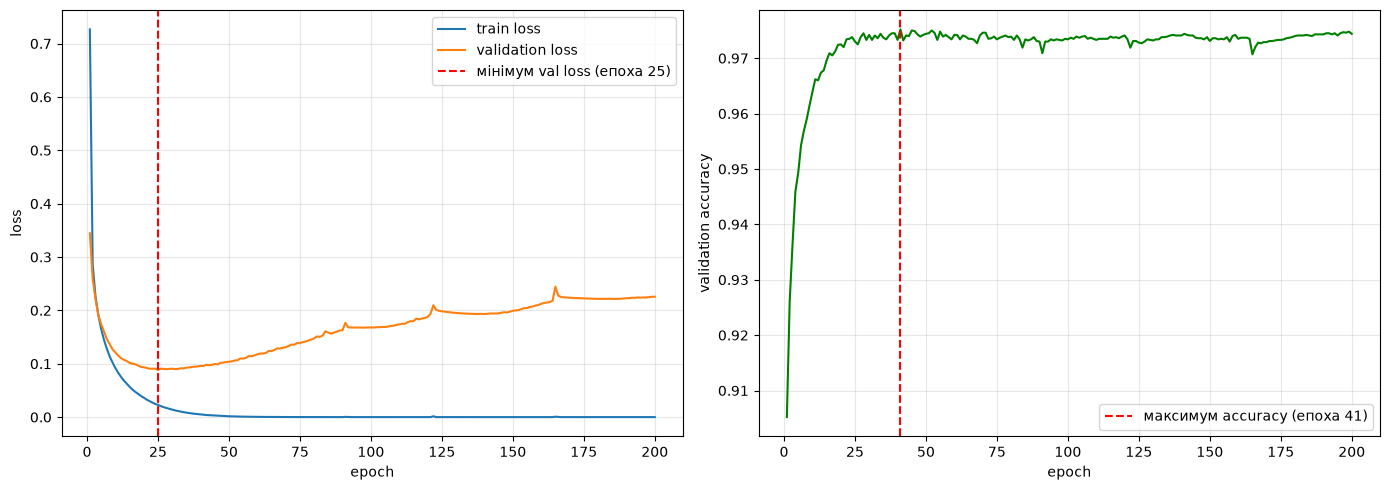

Мінімум validation loss: 0.0884 на епосі 25
Максимум validation accuracy: 0.9752 на епосі 41
Validation loss на епосі 200: 0.2256


In [ ]:
val_loss = np.array(base_history['val_loss'])
val_acc = np.array(base_history['val_acc'])

best_loss_epoch = int(val_loss.argmin()) + 1
best_acc_epoch = int(val_acc.argmax()) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, 201), base_history['train_loss'], label='train loss')
axes[0].plot(range(1, 201), val_loss, label='validation loss')
axes[0].axvline(best_loss_epoch, color='r', linestyle='--', label=f'мінімум val loss (епоха {best_loss_epoch})')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(range(1, 201), val_acc, color='g')
axes[1].axvline(best_acc_epoch, color='r', linestyle='--', label=f'максимум accuracy (епоха {best_acc_epoch})')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('validation accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Мінімум validation loss:", round(val_loss.min(), 4), "на епосі", best_loss_epoch)
print("Максимум validation accuracy:", round(val_acc.max(), 4), "на епосі", best_acc_epoch)
print("Validation loss на епосі 200:", round(val_loss[-1], 4))

In [ ]:
torch.manual_seed(0)
final_net = MNISTNet(100).to(device)
final_optimizer = torch.optim.Adam(final_net.parameters(), lr=1.0e-3)
final_history = train_model(final_net, final_optimizer, epochs=best_loss_epoch)

test_loss, test_accuracy = evaluate(final_net, X_test, y_test)
print(f"Мережа після {best_loss_epoch} епох: test loss = {test_loss:.4f}, test accuracy = {test_accuracy:.4f}")

Мережа після 25 епох: test loss = 0.0823, test accuracy = 0.9751


**Оптимальна кількість епох.** За графіком validation loss мінімальний (0.0884) на 25-й епосі, після чого зростає, хоча train loss продовжує падати до нуля. Validation accuracy виходить на плато близько 0.973–0.975 приблизно з 30-ї епохи, максимум 0.9752 на 41-й епосі, а далі не змінюється. Як оптимальну обрано 25 епох: на цей момент втрата на валідації найменша, а точність уже майже максимальна. Мережа, навчена 25 епох, на тесті дає accuracy 0.9751 при test loss 0.0823. Подальше навчання не покращує точність, а лише збільшує перенавчання.

# Завдання 1g. Повнозв'язний шар через матричне множення

> g. Нехай у нас буде 1 об'єкт x на вході з двома компонентами. Його ми передамо в повнозв'язний шар з 3-ма нейронами і отримаємо, відповідно, 3 виходи. Після цього напишіть цю ж функціональність за допомогою матричного множення. Та перевірте розрахунок похідної.

In [ ]:
x = torch.tensor([[10., 20.]])

fc = torch.nn.Linear(2, 3)

w = torch.tensor([[11., 12.], [21., 22.], [31., 32.]])
fc.weight.data = w

b = torch.tensor([[31., 32., 33.]])
fc.bias.data = b

fc_out = fc(x)

fc_out_summed = fc_out.sum()

fc_out_summed.backward()
weight_grad = fc.weight.grad
bias_grad = fc.bias.grad

w.requires_grad_(True)
b.requires_grad_(True)

fc_out_alternative = x @ w.t() + b

our_formula = fc_out_alternative.sum()

our_formula.backward()

print(fc_out == fc_out_alternative)
print('fc_weight_grad:', weight_grad)
print('our_weight_grad:', w.grad)
print('fc_bias_grad:', bias_grad)
print('out_bias_grad:', b.grad)

tensor([[True, True, True]])
fc_weight_grad: tensor([[10., 20.],
        [10., 20.],
        [10., 20.]])
our_weight_grad: tensor([[10., 20.],
        [10., 20.],
        [10., 20.]])
fc_bias_grad: tensor([[1., 1., 1.]])
out_bias_grad: tensor([[1., 1., 1.]])


Вихід повнозв'язного шару збігається з обчисленим матричним множенням `x @ W^T + b`: `[381, 682, 983]`. Градієнт суми виходів за вагами дорівнює вхідному вектору `[10, 20]` у кожному рядку, а градієнт за зміщеннями дорівнює одиниці для кожного нейрона. Це збігається з аналітичним результатом, адже похідна `sum(x @ W^T + b)` за `W[i, j]` дорівнює `x[j]`, а за `b[i]` дорівнює 1.

# Завдання 2. Нейронна мережа для набору даних CIFAR 10

> Адаптувати розроблену модель для роботи з набором даних CIFAR 10.
>
> Зробіть аналогічні розрахунки та натренуйте модель для набору даних CIFAR 10. Вкажіть, що це за набір даних, особливості, кількість класів, отримані результати, тощо.

In [ ]:
CIFAR_train = torchvision.datasets.CIFAR10('./', download=True, train=True)
CIFAR_test = torchvision.datasets.CIFAR10('./', download=True, train=False)

X_train_c = torch.from_numpy(CIFAR_train.data)
y_train_c = torch.tensor(CIFAR_train.targets)
X_test_c = torch.from_numpy(CIFAR_test.data)
y_test_c = torch.tensor(CIFAR_test.targets)

print(CIFAR_train.classes)
print(X_train_c.shape, X_train_c.dtype, y_train_c.shape)
print(X_test_c.shape, y_test_c.shape)
print("Зображень кожного класу в train:", torch.bincount(y_train_c).tolist())
print("Діапазон значень пікселів:", X_train_c.min().item(), X_train_c.max().item())

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
torch.Size([50000, 32, 32, 3]) torch.uint8 torch.Size([50000])
torch.Size([10000, 32, 32, 3]) torch.Size([10000])
Зображень кожного класу в train: [5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]
Діапазон значень пікселів: 0 255


CIFAR 10 це набір кольорових (RGB) зображень розміром 32 на 32 пікселі. Він містить 60 000 зображень, розбитих на 10 класів по 6000 на кожен, з яких 50 000 призначено для навчання, а 10 000 для тесту. Кожен піксель закодований значеннями від 0 до 255 для кожного з трьох каналів, тому повнозв'язний нейрон у першому шарі має приймати 32 × 32 × 3 = 3072 значення. Канал кольору в цьому наборі стоїть останнім, а PyTorch очікує його другим, тому розмірності переставляються через `permute`.

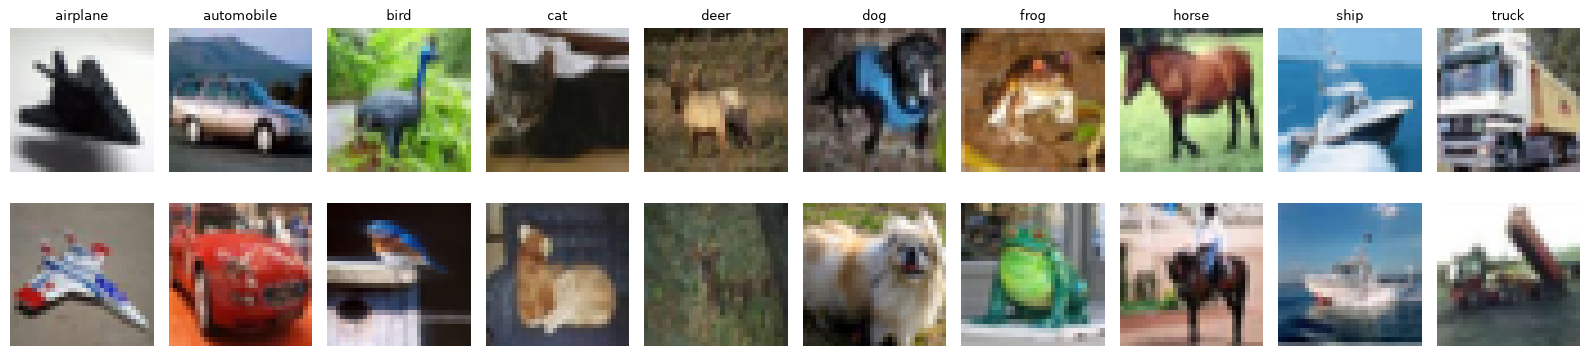

In [ ]:
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for class_index in range(10):
    indexes = (y_train_c == class_index).nonzero().flatten()[:2]
    for row, idx in enumerate(indexes):
        axes[row, class_index].imshow(X_train_c[idx].numpy())
        axes[row, class_index].axis('off')
        if row == 0:
            axes[row, class_index].set_title(CIFAR_train.classes[class_index], fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
X_train_c = X_train_c.float() / 255.
X_test_c = X_test_c.float() / 255.

X_train_c = X_train_c.permute(0, 3, 1, 2)
X_test_c = X_test_c.permute(0, 3, 1, 2)

print(X_train_c.shape, X_test_c.shape)

X_train_c = X_train_c.reshape(len(X_train_c), -1)
X_test_c = X_test_c.reshape(len(X_test_c), -1)

generator = torch.Generator().manual_seed(0)
permutation = torch.randperm(len(X_train_c), generator=generator)
val_idx_c, train_idx_c = permutation[:5000], permutation[5000:]

X_val_c, y_val_c = X_train_c[val_idx_c].to(device), y_train_c[val_idx_c].to(device)
X_tr_c, y_tr_c = X_train_c[train_idx_c].to(device), y_train_c[train_idx_c].to(device)
X_test_c, y_test_c = X_test_c.to(device), y_test_c.to(device)

print(X_tr_c.shape, X_val_c.shape, X_test_c.shape)

torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
torch.Size([45000, 3072]) torch.Size([5000, 3072]) torch.Size([10000, 3072])


Пікселі нормуються діленням на 255, тож значення лежать у діапазоні від 0 до 1, а кожне зображення розтягується у вектор із 3072 значень. З 50 000 тренувальних зображень 5000 відокремлюється для валідації.

## Навчання моделей

In [ ]:
class FCNet(torch.nn.Module):
    def __init__(self, n_in, hidden_sizes, activation, n_out=10):
        super(FCNet, self).__init__()
        layers = []
        previous = n_in
        for size in hidden_sizes:
            layers.append(torch.nn.Linear(previous, size))
            layers.append(activation())
            previous = size
        layers.append(torch.nn.Linear(previous, n_out))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

cifar_configs = {
    'базова (100 нейронів, Sigmoid)': ((100,), torch.nn.Sigmoid),
    '1 шар 512, ReLU': ((512,), torch.nn.ReLU),
    '2 шари 512-256, ReLU': ((512, 256), torch.nn.ReLU),
}

cifar_models = {}
cifar_histories = {}
EPOCHS_C = 30

for name, (hidden, activation) in cifar_configs.items():
    torch.manual_seed(0)
    net = FCNet(3 * 32 * 32, hidden, activation).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1.0e-3)
    history = train_model(net, opt, epochs=EPOCHS_C, X_tr=X_tr_c, y_tr=y_tr_c, X_va=X_val_c, y_va=y_val_c)
    cifar_models[name] = net
    cifar_histories[name] = history
    print(name, "- готово")

базова (100 нейронів, Sigmoid) - готово


1 шар 512, ReLU - готово


2 шари 512-256, ReLU - готово


                                параметрів  найкраща епоха  train loss (кінець)  val loss (мін)  val accuracy (макс)
модель                                                                                                              
базова (100 нейронів, Sigmoid)      308310              28               1.2632          1.4182               0.4920
1 шар 512, ReLU                    1578506              25               1.2456          1.4128               0.5038
2 шари 512-256, ReLU               1707274              25               0.9973          1.3731               0.5268


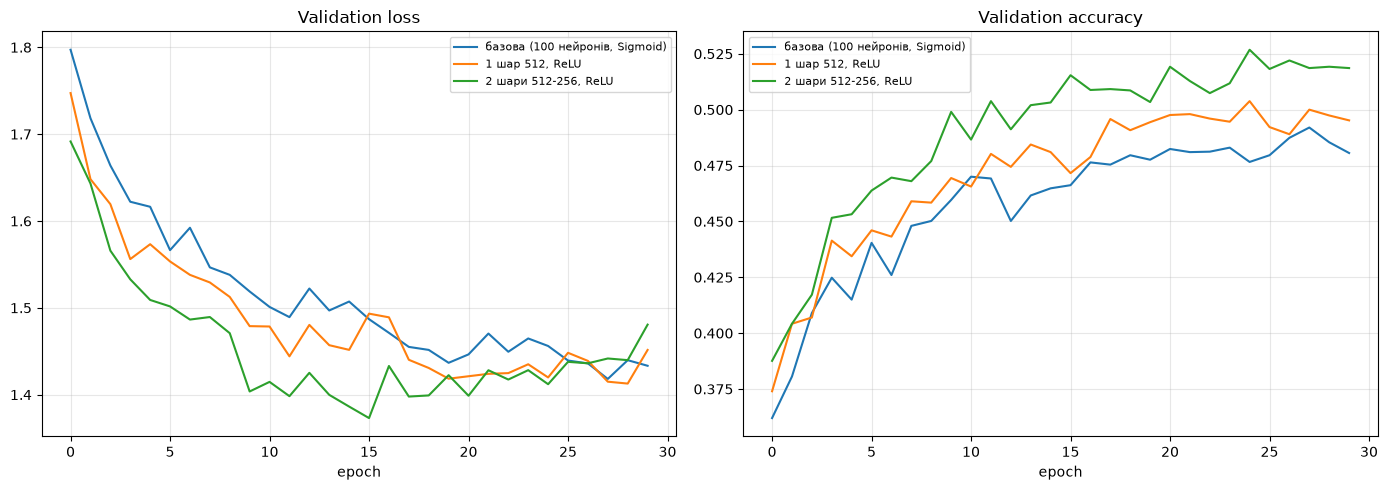

In [ ]:
rows = []
for name, history in cifar_histories.items():
    best_epoch = int(np.argmax(history['val_acc'])) + 1
    rows.append({
        'модель': name,
        'параметрів': sum(p.numel() for p in cifar_models[name].parameters()),
        'найкраща епоха': best_epoch,
        'train loss (кінець)': history['train_loss'][-1],
        'val loss (мін)': min(history['val_loss']),
        'val accuracy (макс)': max(history['val_acc']),
    })

table_c = pd.DataFrame(rows).set_index('модель')
print(table_c.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in cifar_histories.items():
    axes[0].plot(history['val_loss'], label=name)
    axes[1].plot(history['val_acc'], label=name)
axes[0].set_title('Validation loss')
axes[1].set_title('Validation accuracy')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Результати на тесті

In [ ]:
best_name = table_c['val accuracy (макс)'].idxmax()
best_epochs = int(table_c.loc[best_name, 'найкраща епоха'])
hidden, activation = cifar_configs[best_name]

torch.manual_seed(0)
best_cifar = FCNet(3 * 32 * 32, hidden, activation).to(device)
opt = torch.optim.Adam(best_cifar.parameters(), lr=1.0e-3)
train_model(best_cifar, opt, epochs=best_epochs, X_tr=X_tr_c, y_tr=y_tr_c, X_va=X_val_c, y_va=y_val_c)

test_loss_c, test_acc_c = evaluate(best_cifar, X_test_c, y_test_c)
print("Обрана модель:", best_name, "| епох:", best_epochs)
print(f"Test loss = {test_loss_c:.4f}, test accuracy = {test_acc_c:.4f}")

with torch.no_grad():
    test_pred = best_cifar(X_test_c).argmax(dim=1)

per_class = pd.Series({
    CIFAR_train.classes[i]: (test_pred[y_test_c == i] == i).float().mean().item() for i in range(10)
}).sort_values(ascending=False)
print("Точність за класами:")
print(per_class.round(3).to_string())

Обрана модель: 2 шари 512-256, ReLU | епох: 25
Test loss = 1.4101, test accuracy = 0.5198
Точність за класами:
ship          0.705
truck         0.614
horse         0.591
airplane      0.561
automobile    0.559
frog          0.543
deer          0.479
bird          0.410
cat           0.377
dog           0.359


**Аналіз результатів.** Це набір кольорових зображень об'єктів 10 класів (літак, автомобіль, птах, кіт, олень, собака, жаба, кінь, корабель, вантажівка) по 5000 на клас у тренувальній вибірці, тобто класи збалансовані. Зображення значно складніші за цифри MNIST: різні фони, ракурси та кольори, тому повнозв'язній мережі складніше.

Усі три мережі навчались 30 епох. Базова мережа з теорії (100 нейронів, Sigmoid) досягла validation accuracy 0.492, мережа з одним шаром на 512 нейронів і ReLU 0.504, а мережа з двома шарами 512-256 і ReLU 0.527. Найкращою обрано останню (близько 25 епох, після чого validation loss починає зростати). На тестовій вибірці вона дала accuracy 0.520 при test loss 1.41, що значно нижче за 0.975 на MNIST.

Найкраще розпізнаються корабель (0.705), вантажівка (0.614) і кінь (0.591), а гірше за все собака (0.359), кіт (0.377) і птах (0.410). Схожі тварини плутаються між собою. Повнозв'язна мережа розтягує зображення у вектор і не бачить просторового розташування пікселів, тому для таких зображень вона працює обмежено. Для підвищення якості потрібні мережі, що враховують структуру зображення.

# Висновки

У цьому практикумі ми навчились будувати повнозв'язну нейронну мережу для класифікації зображень у PyTorch: завантажувати набори MNIST і CIFAR 10, готувати зображення (перетворення в числа з плаваючою комою, нормування, розтягування у вектор), навчати мережу по батчах, будувати графіки втрат і відстежувати перенавчання, порівнювати методи градієнтного спуску та реалізовувати повнозв'язний шар вручну. Метою завдання було засвоїти принцип побудови повнозв'язної нейронної мережі для класифікації зображень, і її досягнуто.

**MNIST.** Оптимальною виявилась мережа 784-100-10 із сигмоїдою в прихованому шарі, оптимізатором Adam зі швидкістю навчання 1e-3, батчем 100 і нормованими пікселями, яку слід навчати близько 25 епох: це мінімум validation loss. Така мережа дає accuracy 0.975 на тесті. Довше навчання (до 200 епох) точність не покращує, а лише призводить до перенавчання (validation loss зростає з 0.088 до 0.226). Серед методів градієнтного спуску найкращими виявились адаптивні Adam і RMSprop (accuracy 0.96–0.97 за 10 епох), SGD із моментом помітно слабший (до 0.925), а звичайний SGD найгірший (0.50 при швидкості 1e-3). Власна реалізація `torch.nn.Linear` повністю збігається з оригіналом за виходами, градієнтами й результатом навчання, а `cudnn.deterministic = True` на повнозв'язній мережі навчання не сповільнює і забезпечує відтворюваність.

**CIFAR 10.** Найкращою серед перевірених стала мережа 3072-512-256-10 з активацією ReLU, Adam 1e-3 і приблизно 25 епохами. Вона дає accuracy 0.52 на тесті, значно менше, ніж на MNIST. Причина в тому, що зображення CIFAR 10 складніші, а повнозв'язна мережа не враховує просторову структуру картинки, тому плутає схожі класи (собака, кіт, птах). Більші мережі та ReLU покращують результат лише на кілька відсотків, а подальший прогрес потребує архітектур, що працюють із просторовою структурою зображення.

# Контрольні питання

**1. Що являє собою повнозв'язна нейронна мережа?**

Повнозв'язна нейронна мережа складається з повнозв'язних шарів (fully connected, у PyTorch це `torch.nn.Linear`), у яких кожен нейрон з'єднаний з усіма виходами попереднього шару. Кожен такий шар множить вхід на матрицю ваг і додає зміщення, а між шарами ставиться функція активації (наприклад, сигмоїда), яка вносить нелінійність. Для зображень картинку розтягують у довгий вектор, наприклад 28 × 28 = 784 пікселі для MNIST, тому частина інформації про сусідство пікселів губиться, але для малих зображень цього достатньо. Остання частина мережі має стільки виходів, скільки класів, а передбачений клас це індекс найбільшого виходу.

**2. Що являє собою набір даних CIFAR 10?**

CIFAR-10 це один із найбільш широко використовуваних наборів зображень для навчання алгоритмів машинного навчання і комп'ютерного зору. Він складається з 60 000 кольорових RGB-зображень розміром 32 × 32 пікселі, які розбито на 10 класів по 6000 зображень на клас: 50 000 картинок для навчання та 10 000 тестових. Кожен піксель кодується значеннями від 0 до 255 для кожного з трьох каналів, тому для повнозв'язної мережі вхід становить 32 × 32 × 3 = 3072 значення. Значення зазвичай нормують діленням на 255, а канал кольору переставляють на другу позицію методом `permute`.